In [1]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset , DataLoader
import torch.optim as optim
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report , confusion_matrix

import warnings
warnings.filterwarnings("ignore")

plt.style.use('default')
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12

In [3]:
np.random.seed(42)
torch.manual_seed(42)

In [4]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


In [5]:
if torch.cuda.is_available():
    print(f"Running on : {torch.cuda.get_device_name()}")
    print(f"Total Device : {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")
else:
    print("   Running on CPU")

print(f"Library Versions:")
print(f"PyTorch: {torch.__version__}")
print(f"NumPy: {np.__version__}")
print(f"Matplotlib: {plt.matplotlib.__version__}")

print("\n✅ Environment setup complete!")


Running on : NVIDIA GeForce RTX 4060 Laptop GPU
Total Device : 8.0 GB
Library Versions:
PyTorch: 2.11.0+cu128
NumPy: 2.4.1
Matplotlib: 3.10.8

✅ Environment setup complete!


=== Horizontal Edge Detection Kernel ===


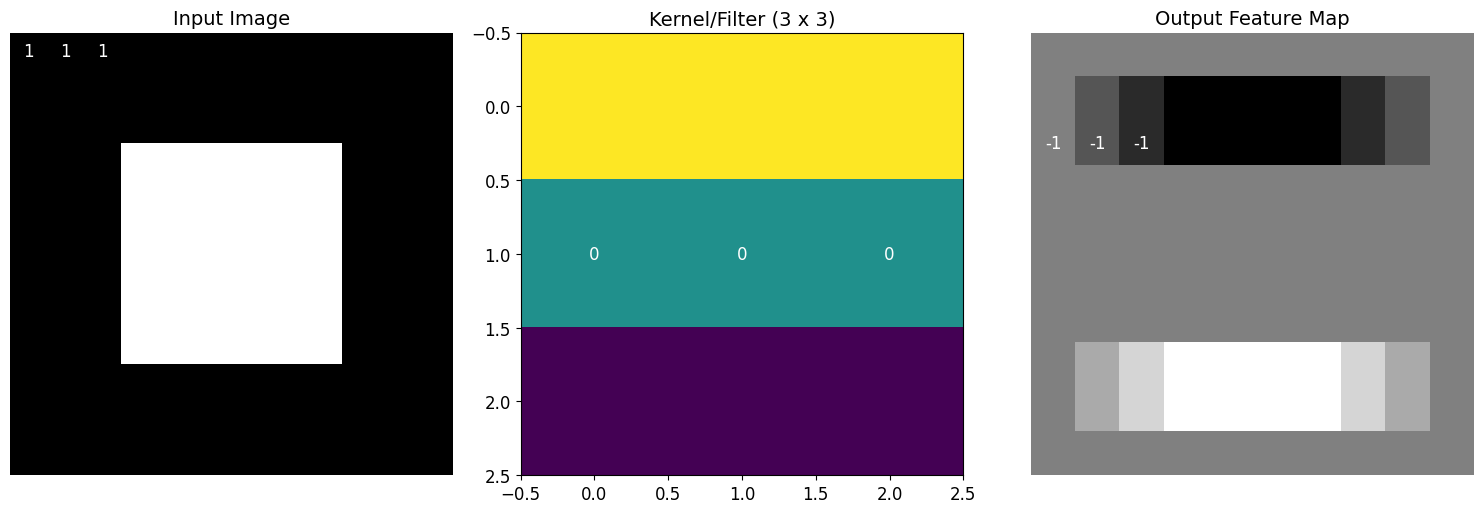

=== Vertical Edge Detection Kernel ===


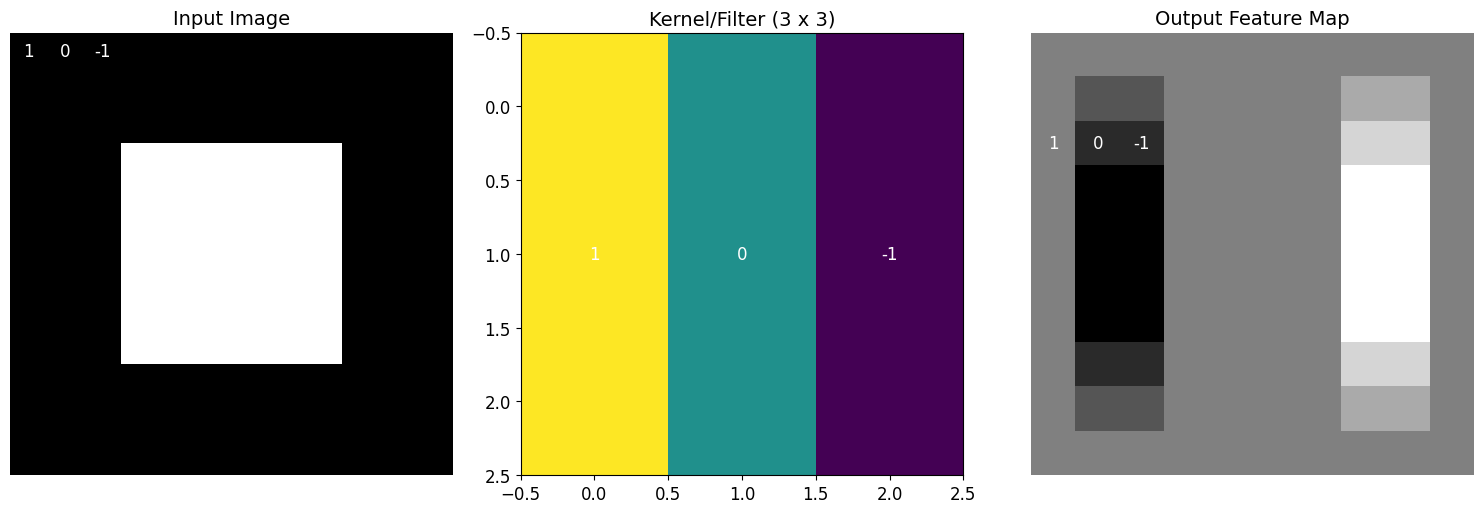

=== Sharpening Kernel ===


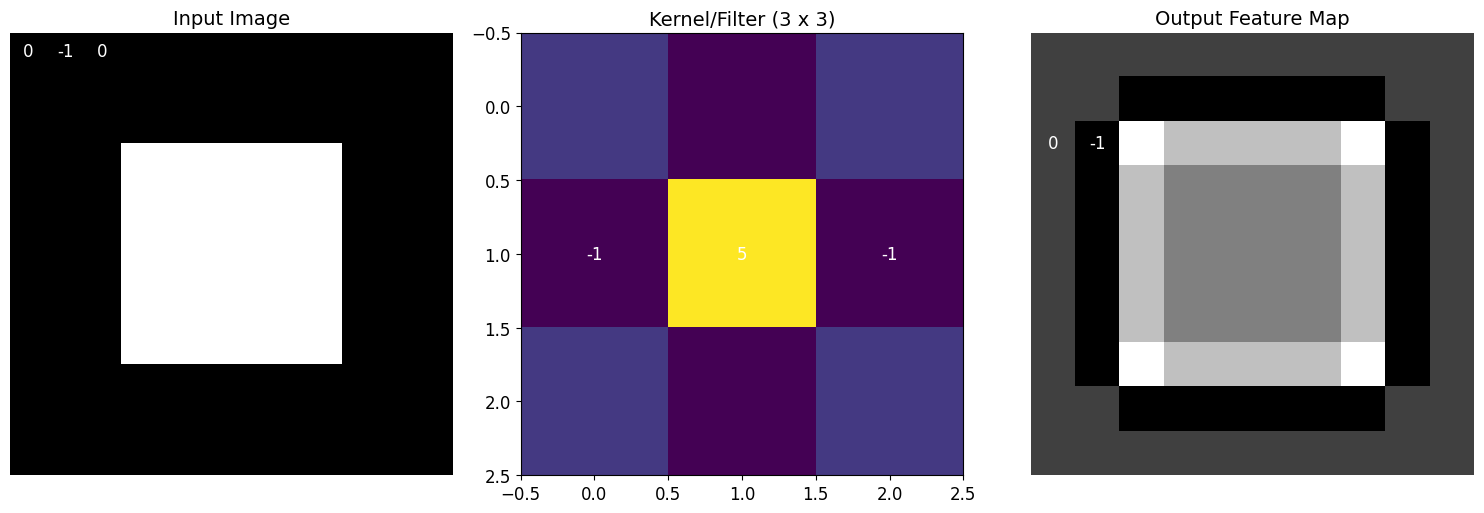

In [6]:
def visualize_convolution(image , kernel , feature_map):
    """ visualize the convolution operation with an image , kernal and resulting Featuer Map """

    fig , axes = plt.subplots(1 , 3 , figsize=(15 , 5))

    # Display the input Image
    axes[0].imshow(image , cmap = "gray")
    axes[0].set_title("Input Image" , fontsize = 14)
    axes[0].axis("off")

    # Display the kernal/filter
    # use a diverge colormap for kernels with positive and negative values
    axes[1].imshow(kernel , cmap = "viridis")
    axes[1].set_title(f"Kernel/Filter ({kernel.shape[0]} x {kernel.shape[1]})" , fontsize=14)

    # Add Annotation for kernel values
    for i in range(kernel.shape[0]):
        for j in range(kernel.shape[1]):
            axes[i].text(j , i , f"{kernel[i,j]}" , ha = "center" , va = "center" , color = "white" , fontsize = 12)

    # Display the resulting Feature Map
    axes[2].imshow(feature_map , cmap = "gray")
    axes[2].set_title("Output Feature Map" , fontsize = 14)
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

    # Create a simple 12x12 image with a white square
# This pattern has clear horizontal and vertical edges, perfect for this demo.
image = np.zeros((12, 12))
image[3:9, 3:9] = 1 # A 6x6 white square in the middle

# Define different kernels to demonstrate filter effects
kernels = {
    "Horizontal Edge Detection": np.array([
        [1, 1, 1],
        [0, 0, 0],
        [-1, -1, -1]
    ]),
    "Vertical Edge Detection": np.array([
        [1, 0, -1],
        [1, 0, -1],
        [1, 0, -1]
    ]),
    "Sharpening": np.array([
        [0, -1, 0],
        [-1, 5, -1],
        [0, -1, 0]
    ])
}

# Manual 2D convolution for demonstration
def convolve2d_manual(image, kernel):
    # Get dimensions
    i_height, i_width = image.shape
    k_height, k_width = kernel.shape

    # Calculate output dimensions (assuming 'valid' convolution without padding)
    o_height = i_height - k_height + 1
    o_width = i_width - k_width + 1

    # Initialize output feature map
    output = np.zeros((o_height, o_width))

    # Perform convolution
    for i in range(o_height):
        for j in range(o_width):
            # Extract the current window
            window = image[i:i+k_height, j:j+k_width]
            # Element-wise multiplication and sum
            output[i, j] = np.sum(window * kernel)

    return output

# Display convolution results for each kernel
for name, kernel in kernels.items():
    # Apply convolution
    feature_map = convolve2d_manual(image, kernel)

    # Normalize feature map for better visualization (maps values to [0, 1])
    # Add a small epsilon to avoid division by zero if the feature map is flat
    f_min, f_max = feature_map.min(), feature_map.max()
    if f_max - f_min > 1e-8:
        feature_map = (feature_map - f_min) / (f_max - f_min)
    else:
        # If the map is all one value, just set it to a uniform gray
        feature_map = np.full_like(feature_map, 0.5)


    print(f"=== {name} Kernel ===")
    visualize_convolution(image, kernel, feature_map)